# Single Fidelity Surrogate Model Comparison

This workbook is aimed at testing the convergence of single fidelity models to data sets taken from analytical functions. The goal is to show how the functions increase in accuracy as the number of samples increase.

In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import examples.multi_fidelity_functions as mfs
from SurrogateModels import mfsnn
from torch import nn as tnn

The following creates some scaffolding for systematically creating and assessing kriging models.

In [3]:
import time
import csv


def create_test_points(func: mfs.MultiFidelityTemplate, n=2000):
    # Create a set of samples to create a ground truth
    X_test = func.sample_random(n)
    y_test = func.high_fidelity(X_test)
    return X_test, y_test


def generate_nn_model(
    name,
    func: mfs.MultiFidelityTemplate,
    n,
    seed,
    X_test,
    y_test,
    hidden_layer_size=[20, 20, 20],
    learning_rate=1e-4,
    weight_decay=1e-6,
    activation=tnn.Tanh(),
    epochs=1000,
    x_transform=True,
    bounds=None,
):
    X_train = func.sample_random(n, seed=seed)
    # X_train = func.sample_uniform(n)
    y_train = func.high_fidelity(X_train)
    print(f"y mean = {y_train.mean()}")
    
    print(f"y max = {y_train.max()}")
    training_data = zip(X_train, y_train)
    with open("training_data.txt", "w") as file:
        for row in training_data:
            file.write(f"{row[0].tolist()},{row[1].tolist()}\n")
    # Setup timer to gauge model training time
    t0 = time.perf_counter()
    model = mfsnn.MLPNetwork(
        X=X_train,
        y=y_train,
        X_test=X_test,
        y_test=y_test,
        activation=activation,
        hidden_layer_size=hidden_layer_size,
        epochs=epochs,
        learning_rate=learning_rate,
        weight_decay=weight_decay,
        scale_input=x_transform,
        bounds = bounds
    )
    model_training_time = time.perf_counter() - t0

    t0 = time.perf_counter()
    error = model.model_error(X_test, y_test)
    evaluation_time = time.perf_counter() - t0
    print(
        f"Run {name} :: seed {seed} :: points {n} :: error {error} :: train_time {model_training_time} :: evaluation_time {evaluation_time}"
    )
    return model, error, model_training_time, evaluation_time


def generate_model_comparisons(
    name,
    func: mfs.MultiFidelityTemplate,
    X_test,
    y_test,
    sample_low=5,
    sample_high=105,
    step_size=5,
    seeds=5,
    points=[],
    model_error=[],
    training_time=[],
    evaluation_time=[],
    hidden_layer_size=[20, 20, 20],
    learning_rate=1e-4,
    output_file="model_comparison_output.csv",
):
    # Generate a Kriging model of the data and test accuracy using a number of random sample points
    n_points = list(range(sample_low, sample_high, step_size))
    for seed in range(0, seeds):
        for n in n_points:
            X_train = func.sample_random(n, seed=seed)
            # X_train = func.sample_uniform(n)
            y_train = func.high_fidelity(X_train)
            # Setup timer to gauge model training time
            t0 = time.perf_counter()

            model = mfsnn.MLPNetwork(
                X=X_train,
                y=y_train,
                X_test=X_test,
                y_test=y_test,
                activation=tnn.Tanh(),
                hidden_layer_size=hidden_layer_size,
                epochs=1000,
                learning_rate=learning_rate,
                weight_decay=1e-6,
                bounds = func.bounds,
                scale_input=True,
            )

            training_time.append(time.perf_counter() - t0)

            t0 = time.perf_counter()
            error = model.model_error(X_test, y_test)
            evaluation_time.append(time.perf_counter() - t0)
            model_error.append(model.model_error(X_test, y_test))
            points.append(n)
            print(
                f"Run {name} :: seed {seed} :: points {n} :: error {error} :: train_time {training_time[-1]} "
            )
            with open(output_file, "w", newline="") as file:
                writer = csv.writer(file)
                writer.writerow(
                    [
                        points[-1],
                        model_error[-1],
                        training_time[-1],
                        evaluation_time[-1],
                    ]
                )
    return points, model_error, evaluation_time, training_time


def plot_error_measure(
    points, error, name, color="blue", marker="o", label="Test", ax=None
):
    if ax == None:
        fig = plt.figure(name)
        ax = fig.add_subplot()
    ax.set_title(name)
    ax.scatter(
        points,
        error,
        color=color,
        label=label,
        marker=marker,
    )
    ax.set_xlabel("Samples")
    ax.set_ylabel("RMS Error")
    ax.legend()
    ax.grid()
    ax.set_yscale("log")
    return ax


def export_to_csv(output_file, points, model_error, training_time, evaluation_time):
    with open(output_file, "w", newline="") as file:
        writer = csv.writer(file)
        for i, val in enumerate(points):
            writer.writerow(
                [
                    val,
                    model_error[i],
                    training_time[i],
                    evaluation_time[i],
                ]
            )

In [13]:
key = "2D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = create_test_points(my_function, n=3000)

model, error, model_training_time, evaluation_time = generate_nn_model(
    name=key,
    func=my_function,
    n=1000,
    seed=0,
    X_test=X_test,
    y_test=y_test,
    hidden_layer_size=[20, 20, 20],
    learning_rate=1e-3,
    weight_decay=0,
    activation=tnn.Tanh(),
    epochs=20000,
    x_transform=True,
    bounds=my_function.bounds,
)

Run 2D :: seed 0 :: points 1000 :: error 0.030936723787415615 :: train_time 1829.8377193000633 :: evaluation_time 0.0025275000371038914


[1.9198174976992073, 1.9108756803180849, 1.902363489193503, 1.8942875970898088, 1.886655186437359, 1.8794707086852693, 1.8727360090538478, 1.8664505912971332, 1.860611704662567, 1.8552148906314148, 1.850253000228876, 1.8457163007962254, 1.8415923343807132, 1.8378654583658183, 1.834516714103625, 1.8315238331278432, 1.828861381700634, 1.8265010435078937, 1.824412300902091, 1.8225627301256109, 1.8209192140812303, 1.8194475861474528, 1.8181150868480955, 1.816889741599606, 1.8157416327566154, 1.8146435131629854, 1.8135713502169912, 1.8125042750867215, 1.8114251863307018, 1.8103210242512093, 1.8091814639298873, 1.8080003724857385, 1.8067741715843992, 1.8055021750881517, 1.8041857397585133, 1.8028280744245213, 1.801433850448443, 1.800008347280009, 1.7985575883610518, 1.7970876153295978, 1.7956043560621926, 1.7941132260785861, 1.7926188607490803, 1.7911254449785639, 1.7896359786378782, 1.7881529382458456, 1.7866776075075619, 1.7852105397456268, 1.7837513543640426, 1.782299468757085, 1.78085342

<Axes3D: title={'center': 'Data'}, xlabel='x1', ylabel='x2', zlabel='f(x)'>

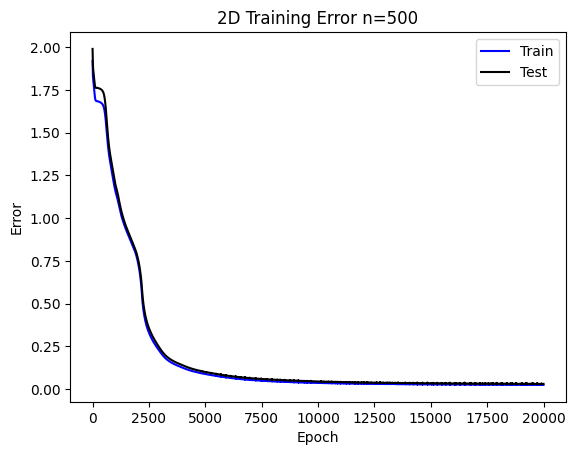

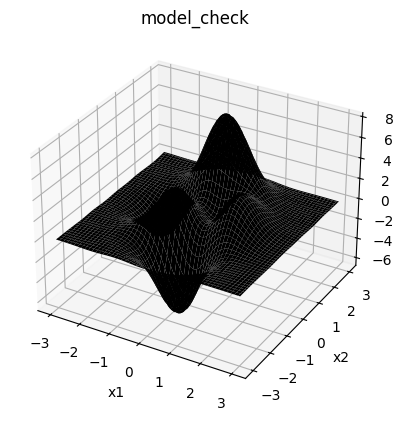

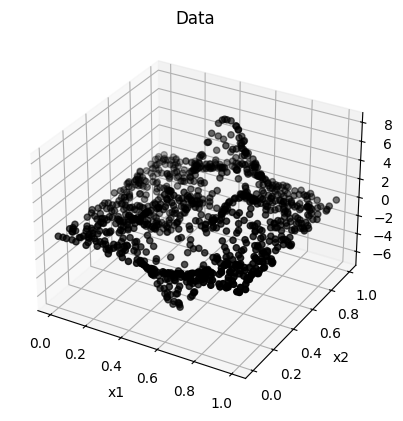

In [14]:
model.plot_training_error("2D Training Error n=500")
print(model.training_error)
model.plot_model(my_function.bounds,"model_check")
model.plot_data()

In [ ]:
key = "2D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = create_test_points(my_function, n=3000)

points=[]
model_error=[]
training_time=[]
evaluation_time=[]
iterations = []
points, model_error, evaluation_time, training_time = generate_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=50,
    sample_high=1000,
    step_size=100,
    seeds=3,    
    points=points,
    model_error=model_error,
    training_time=training_time,
    evaluation_time=evaluation_time,
    hidden_layer_size=[20,20,20],
    learning_rate=1e-3
)

### 4-Dimensional Dataset

In [ ]:
key = "4D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = create_test_points(my_function, n=5000)

model_30_30_10, error_30_30_10, model_training_time_30_30_10, evaluation_time_30_30_10 = generate_nn_model(
    name=key,
    func=my_function,
    n=1000,
    seed=1,
    X_test=X_test,
    y_test=y_test,
    hidden_layer_size=[30,30,10],
    learning_rate=1e-3,
    weight_decay=0,
    activation=tnn.Tanh(),
    epochs=30000,
    x_transform=False,
    bounds=my_function.bounds,
)

In [ ]:
key = "4D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = create_test_points(my_function, n=5000)

model_30_30_10, error_30_30_10, model_training_time_30_30_10, evaluation_time_30_30_10 = generate_nn_model(
    name=key,
    func=my_function,
    n=1000,
    seed=1,
    X_test=X_test,
    y_test=y_test,
    hidden_layer_size=[30,30,10],
    learning_rate=1e-3,
    weight_decay=0,
    activation=tnn.Tanh(),
    epochs=30000,
    x_transform=False,
    bounds=my_function.bounds,
)
model_20_20_10, error_20_20_10, model_training_time_20_20_10, evaluation_time_20_20_10 = generate_nn_model(
    name=key,
    func=my_function,
    n=1000,
    seed=1,
    X_test=X_test,
    y_test=y_test,
    hidden_layer_size=[20,20,10],
    learning_rate=1e-3,
    weight_decay=0,
    activation=tnn.Tanh(),
    epochs=30000,
    x_transform=False,
    bounds=my_function.bounds,
)
model_30_20_10, error_30_20_10, model_training_time_30_20_10, evaluation_time_30_20_10 = generate_nn_model(
    name=key,
    func=my_function,
    n=1000,
    seed=1,
    X_test=X_test,
    y_test=y_test,
    hidden_layer_size=[30,20,10],
    learning_rate=1e-3,
    weight_decay=0,
    activation=tnn.Tanh(),
    epochs=30000,
    x_transform=False,
    bounds=my_function.bounds,
)
model_20_20_5, error_20_20_5, model_training_time_20_20_5, evaluation_time_20_20_5 = generate_nn_model(
    name=key,
    func=my_function,
    n=1000,
    seed=1,
    X_test=X_test,
    y_test=y_test,
    hidden_layer_size=[20,20,5],
    learning_rate=1e-3,
    weight_decay=0,
    activation=tnn.Tanh(),
    epochs=30000,
    x_transform=False,
    bounds=my_function.bounds,
)

y mean = 137.34520207423193
y max = 618.6308082190952
[[-0.41102364  0.91009907 -0.46028832  0.1661027 ]
 [ 0.30137634  0.45715335 -0.10565541  0.2651816 ]
 [-0.25109919  0.65194488 -0.11550703  0.10892371]
 ...
 [-0.95671765 -0.92704348  0.4898438   0.51645174]
 [-0.4763468  -0.77679702  0.36745116 -0.54103873]
 [-0.25659914  0.24306338 -0.09688199 -0.68122621]]
tensor(29835.5391, grad_fn=<MseLossBackward0>)
tensor(28612.1387, grad_fn=<MseLossBackward0>)
tensor(27302.1191, grad_fn=<MseLossBackward0>)
tensor(26347.3633, grad_fn=<MseLossBackward0>)
tensor(25509.4863, grad_fn=<MseLossBackward0>)
tensor(24736.4160, grad_fn=<MseLossBackward0>)
tensor(24010.1094, grad_fn=<MseLossBackward0>)
tensor(23321.8848, grad_fn=<MseLossBackward0>)
tensor(22666.7207, grad_fn=<MseLossBackward0>)
tensor(22041.3281, grad_fn=<MseLossBackward0>)
tensor(21443.3672, grad_fn=<MseLossBackward0>)
tensor(20871.0566, grad_fn=<MseLossBackward0>)
tensor(20322.9648, grad_fn=<MseLossBackward0>)
tensor(19797.9141, grad

In [20]:
X_test,y_test = create_test_points(my_function,n=10)
y_out = model.evaluate(X_test)
print(y_out.shape)
print(y_test.shape)
print(y_out)
print(y_test)

torch.Size([10, 1])
(10, 1)
tensor([[110.6196],
        [115.9797],
        [ 85.0998],
        [320.8877],
        [ 41.3860],
        [141.5575],
        [253.7995],
        [329.4579],
        [ 92.4660],
        [ 29.2227]])
[[110.08480749]
 [116.24068303]
 [ 85.6944229 ]
 [322.20667079]
 [ 40.8209555 ]
 [141.11923264]
 [250.67353532]
 [329.17728651]
 [ 92.86459377]
 [ 29.94769344]]


[172.70834338560485, 172.68699104159526, 172.6656077780836, 172.64421620959388, 172.62279370422087, 172.60132327672056, 172.57978793336432, 172.55819330917035, 172.5365054216788, 172.51474121796085, 172.49286670033635, 172.47088182683186, 172.4487865552408, 172.4265581885517, 172.4041740177714, 172.3816339822053, 172.35892668897367, 172.33602940549025, 172.31294772339368, 172.28963055528038, 172.2660721366079, 172.2422666986823, 172.21818578659165, 172.19382361346473, 172.16914602724265, 172.14414721934347, 172.118827049803, 172.09312863061965, 172.06705746779363, 172.0406020391698, 172.01375649021506, 171.986475213169, 171.95877503779795, 171.9306216817557, 171.90200924145708, 171.8729204419649, 171.84335504137192, 171.81329574206416, 171.78273091502825, 171.75164891857662, 171.72004947188026, 171.68793228922644, 171.65527432364263, 171.62208664679497, 171.58834618608282, 171.55407538513913, 171.51925115165645, 171.48389592757684, 171.4479979924671, 171.4115570053548, 171.374584016635

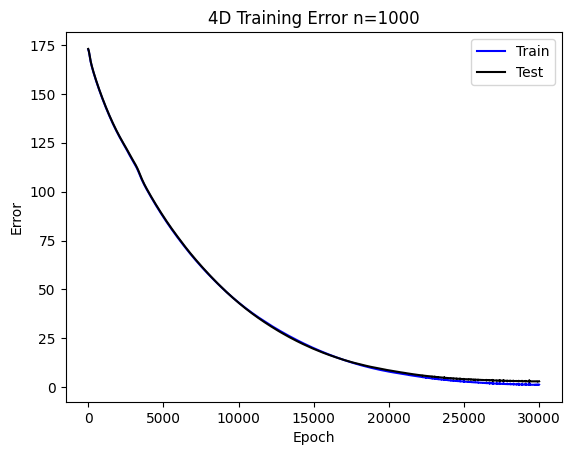

In [ ]:
model_30_30_10.plot_training_error("4D Training Error n=1000")
print(model_30_30_10.training_error)
print(model_30_30_10.model_error(X_test,y_test))
model_30_30_10.plot_model(my_function.bounds,"model_check")
model_30_30_10.plot_data()

[172.7919235037477, 172.77880548551087, 172.765686471229, 172.75254384885335, 172.73937761299536, 172.72616514298, 172.71290077394335, 172.69956752985806, 172.68612580886457, 172.67259820792353, 172.6589394586912, 172.64517215592795, 172.63125667517457, 172.61720995275934, 172.6030262987877, 172.58866041291645, 172.57413488483724, 172.55943269639013, 172.544542482876, 172.5294528750816, 172.5141581599174, 172.49864129899692, 172.4828909087797, 172.4669125876033, 172.4506722950073, 172.43417562036535, 172.41739417036786, 172.40035051987277, 172.3829936054453, 172.36534032941483, 172.34736793573322, 172.32908199140388, 172.31047106168563, 172.29150670085278, 172.27220579833823, 172.2525455635562, 172.232537213501, 172.21215794406038, 172.19140762353678, 172.17028044569713, 172.1487819445726, 172.1269006340235, 172.1046363680392, 172.0819719730251, 172.05894134532795, 172.03551027876483, 172.01168996430155, 171.98747456210293, 171.96288094200736, 171.93789190249774, 171.9125186322974, 171

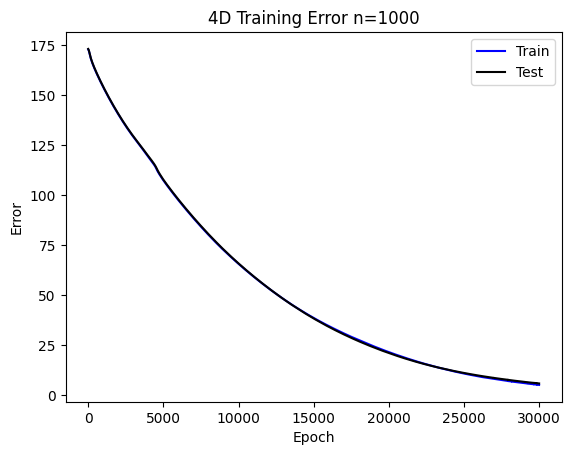

In [9]:
current_model = model_20_20_10
current_model.plot_training_error("4D Training Error n=1000")
print(current_model.training_error)
print(current_model.model_error(X_test,y_test))
current_model.plot_model(my_function.bounds,"model_check")
current_model.plot_data()

[172.79830411855897, 172.77811027622974, 172.7578292817, 172.73747806461978, 172.71705094604874, 172.6965196251071, 172.67590668648594, 172.65517250795008, 172.6342944185048, 172.6133006535128, 172.59214590509325, 172.57084143185952, 172.54935888029257, 172.52772082516188, 172.50589324172378, 172.4838930433071, 172.4616861889185, 172.43930091484364, 172.41669750382357, 172.39389852892126, 172.37087558517536, 172.3476342490665, 172.324151764197, 172.3004280319698, 172.27647995845226, 172.25226776446226, 172.22777999824825, 172.20303355523387, 172.17801130842753, 172.15272448287016, 172.1271219005012, 172.1012374664982, 172.0750426776062, 172.0485373920685, 172.0217271433321, 171.99460043305137, 171.96714007514635, 171.93935158944853, 171.9112291362173, 171.8827725515271, 171.8539873519087, 171.82483358787226, 171.79535654740496, 171.76553900775616, 171.73537510513086, 171.7048817193326, 171.67404160938253, 171.6428659673917, 171.61137168213824, 171.57954150335055, 171.54740370740095, 17

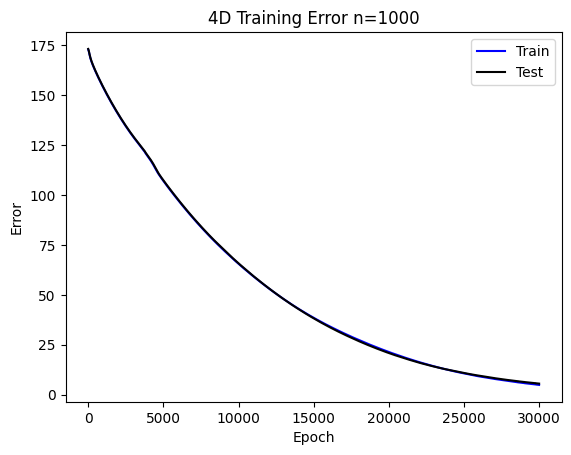

In [ ]:
current_model = model_30_20_10
current_model.plot_training_error("4D Training Error n=1000")
print(current_model.training_error)
print(current_model.model_error(X_test,y_test))
current_model.plot_model(my_function.bounds,"model_check")
current_model.plot_data()

[172.91556601055325, 172.90382419679156, 172.89211547595224, 172.88043420598527, 172.86876344499026, 172.8570975455593, 172.8454308587589, 172.83375773413016, 172.82207251968714, 172.81036391084882, 172.79861494851457, 172.78682562445263, 172.77498462595793, 172.76306367934959, 172.75107972708884, 172.73899318227197, 172.72680967716042, 172.71451788283463, 172.70208950313832, 172.6895245085816, 172.67681155847185, 172.66392799670115, 172.65086247250548, 172.6376092878519, 172.62415708519768, 172.61048884518866, 172.59657056811702, 172.5824304861303, 172.56802327270833, 172.55335452042073, 172.5384128426189, 172.52318684744958, 172.50765947668816, 172.49181932594658, 172.4756606470171, 172.4591890129372, 172.44236469216315, 172.42521589989383, 172.4077028894736, 172.38982554990014, 172.37158943326477, 172.3529660953794, 172.33396674408095, 172.3145629183732, 172.2947828214772, 172.27458097467542, 172.25397423753392, 172.2329567947145, 172.2115171544139, 172.1896608303617, 172.1673706473

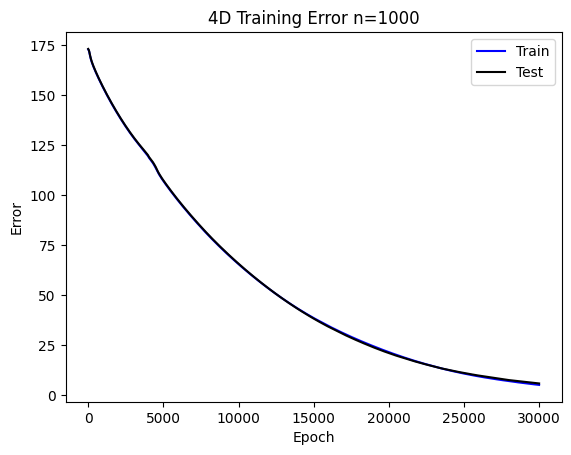

In [11]:
current_model = model_20_20_5
current_model.plot_training_error("4D Training Error n=1000")
print(current_model.training_error)
print(current_model.model_error(X_test,y_test))
current_model.plot_model(my_function.bounds,"model_check")
current_model.plot_data()

In [24]:
key = "8D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = create_test_points(my_function, n=5000)

model, error, model_training_time, evaluation_time = generate_nn_model(
    name=key,
    func=my_function,
    n=1000,
    seed=1,
    X_test=X_test,
    y_test=y_test,
    hidden_layer_size=[20,20,10],
    learning_rate=1e-3,
    weight_decay=0,
    activation=tnn.Tanh(),
    epochs=50000,
    x_transform=False,
    bounds=my_function.bounds,
)

y mean = 41.42463063053078
y max = 121.09770001519058
[[0.19048818 0.72704954 0.94585584 ... 0.85757667 0.1041723  0.3845908 ]
 [0.23845041 0.20597244 0.36424649 ... 0.33921157 0.70869681 0.0235465 ]
 [0.96386596 0.16359689 0.08379654 ... 0.00771959 0.01851481 0.20701926]
 ...
 [0.62397095 0.54157556 0.36121199 ... 0.002818   0.84222739 0.82453155]
 [0.65771913 0.08257667 0.01127806 ... 0.62613676 0.82431555 0.64611228]
 [0.35031438 0.30696516 0.68552044 ... 0.15279725 0.23795896 0.40428258]]
tensor(2748.9858, grad_fn=<MseLossBackward0>)
tensor(2409.0249, grad_fn=<MseLossBackward0>)
tensor(2184.8428, grad_fn=<MseLossBackward0>)
tensor(2030.3569, grad_fn=<MseLossBackward0>)
tensor(1900.4247, grad_fn=<MseLossBackward0>)
tensor(1786.9778, grad_fn=<MseLossBackward0>)
tensor(1686.7438, grad_fn=<MseLossBackward0>)
tensor(1597.8496, grad_fn=<MseLossBackward0>)
tensor(1518.9948, grad_fn=<MseLossBackward0>)
tensor(1449.1663, grad_fn=<MseLossBackward0>)
tensor(1387.5151, grad_fn=<MseLossBackward

KeyboardInterrupt: 

In [ ]:
key = "4D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = create_test_points(my_function, n=3000)

points=[]
model_error=[]
training_time=[]
evaluation_time=[]
iterations = []
points, model_error, evaluation_time, training_time = generate_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=500,
    sample_high=2001,
    step_size=500,
    seeds=3,    
    points=points,
    model_error=model_error,
    training_time=training_time,
    evaluation_time=evaluation_time,
    hidden_layer_size=[20,20,20],
    learning_rate=1e-2
)

In [ ]:
key = "6D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = create_test_points(my_function, n=3000)

points=[]
model_error=[]
training_time=[]
evaluation_time=[]
iterations = []
points, model_error, evaluation_time, training_time = generate_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=500,
    sample_high=10000,
    step_size=500,
    seeds=3,    
    points=points,
    model_error=model_error,
    training_time=training_time,
    evaluation_time=evaluation_time,
    hidden_layer_size=[20,20,10],
    learning_rate=1e-3
)

In [ ]:
report_name = "SingleFidelity4D_Cokriging_260531.csv"
print(model_error)
export_to_csv(
    report_name,
    points=points,
    model_error=model_error,
    training_time=training_time,
    evaluation_time=evaluation_time,
)